In [101]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn import svm


df = pd.read_csv('abalone.data', header=None, names=['Sex', 'Length', 'Diameter', 'Height', 'Whole weight', 'Shucked weight', 'Viscera weight', 'Shell weight', 'Rings'])

In [102]:
df

#Rings is target variable

,Sex,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.1500,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.0700,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.2100,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.1550,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.0550,7
...,...,...,...,...,...,...,...,...,...
4172,F,0.565,0.450,0.165,0.8870,0.3700,0.2390,0.2490,11
4173,M,0.590,0.440,0.135,0.9660,0.4390,0.2145,0.2605,10
4174,M,0.600,0.475,0.205,1.1760,0.5255,0.2875,0.3080,9
4175,F,0.625,0.485,0.150,1.0945,0.5310,0.2610,0.2960,10


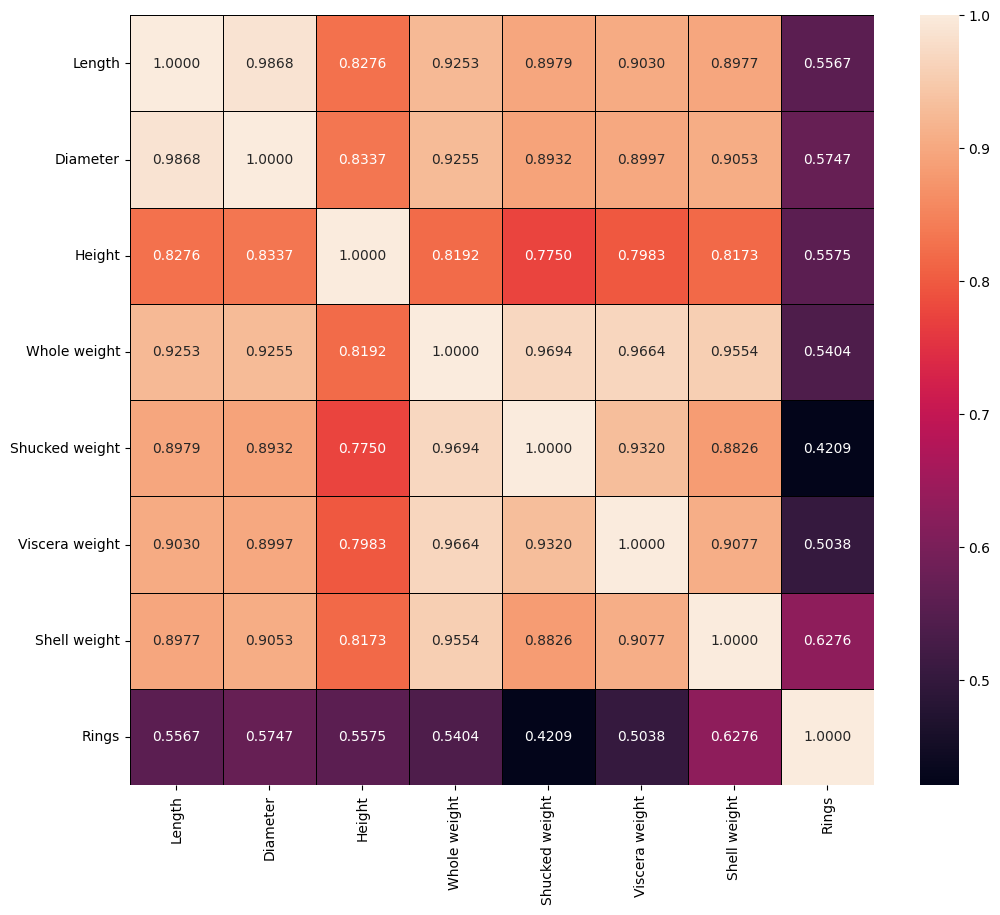

In [103]:
# Visualization of correlation result with seaborn library heatmap.
f, ax = plt.subplots(figsize = (12,10))
sns.heatmap(df.corr(numeric_only=True), annot = True, linewidths=0.5,
            linecolor = "black", fmt = ".4f", ax = ax)
plt.show()

# Classification

## SVM

In [104]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Prepare clean features (the 7 physical measurements) and target ('Sex')
X_cls = df.drop(columns=['Sex', 'Rings'], errors='ignore')
y_cls = df['Sex']

# 80/20 train-test split for models
X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X_cls, y_cls, test_size=0.2, random_state=42, stratify=y_cls
)

# Using a Pipeline prevents data leakage during GridSearchCV scaling
svm_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', random_state=42))
])

param_grid = {
    'svm__C':[1, 10, 100, 1000, 2000, 5000, 10000, 20000],
    'svm__gamma': [0.0005, 0.001, 0.002, 0.005, 0.01, 0.05]
}

grid_svm = GridSearchCV(svm_pipeline, param_grid, cv=5, n_jobs=-1)
grid_svm.fit(X_train_cls, y_train_cls)

print("Best SVM Parameters:", grid_svm.best_params_)
print(f"Best cross-validation score: {grid_svm.best_score_:.4f}")
y_pred_svm = grid_svm.predict(X_test_cls)

print("\n=== SVM Classification Report (Test Set) ===")
print(classification_report(y_test_cls, y_pred_svm))

print("=== Confusion Matrix ===")
print(confusion_matrix(y_test_cls, y_pred_svm))

Best SVM Parameters: {'svm__C': 5000, 'svm__gamma': 0.001}
Best cross-validation score: 0.5615

=== SVM Classification Report (Test Set) ===
              precision    recall  f1-score   support

           F       0.56      0.15      0.24       261
           I       0.64      0.81      0.71       269
           M       0.47      0.65      0.55       306

    accuracy                           0.55       836
   macro avg       0.56      0.54      0.50       836
weighted avg       0.55      0.55      0.50       836

=== Confusion Matrix ===
[[ 39  44 178]
 [  6 219  44]
 [ 25  81 200]]


## Random Forest

In [105]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix


warnings.filterwarnings('ignore')

In [106]:
df = pd.read_csv('abalone.data', header=None, names=['Sex', 'Length', 'Diameter', 'Height', 'Whole weight', 'Shucked weight', 'Viscera weight', 'Shell weight', 'Rings'])

In [107]:
# Re-extract clean X and y (target = Sex) from original DataFrame
y_rf = df['Sex'].values
X_rf = df.drop(columns=['Sex', 'Rings'], errors='ignore').values

# 80/20 train-test split for models
X_train_rf, X_test_rf, y_train_rf, y_test_rf = train_test_split(
    X_rf, y_rf, test_size=0.2, random_state=42, stratify=y_rf)

# Scaling features for RF
scaler_rf = StandardScaler()
X_train_rf_scaled = scaler_rf.fit_transform(X_train_rf)
X_test_rf_scaled = scaler_rf.transform(X_test_rf)

# Instantiate and fit RandomForestClassifier
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)
rf_classifier.fit(X_train_rf_scaled, y_train_rf)

# Predict on testing set
y_pred_rf = rf_classifier.predict(X_test_rf_scaled)

# Evaluation
print("=== Random Forest Classification Report ===")
print(classification_report(y_test_rf, y_pred_rf, target_names=['F', 'I', 'M']))

print("=== Confusion Matrix ===")
print(confusion_matrix(y_test_rf, y_pred_rf))

=== Random Forest Classification Report ===
              precision    recall  f1-score   support

           F       0.46      0.36      0.40       261
           I       0.69      0.78      0.73       269
           M       0.45      0.48      0.46       306

    accuracy                           0.54       836
   macro avg       0.53      0.54      0.53       836
weighted avg       0.53      0.54      0.53       836

=== Confusion Matrix ===
[[ 94  31 136]
 [ 17 210  42]
 [ 95  65 146]]


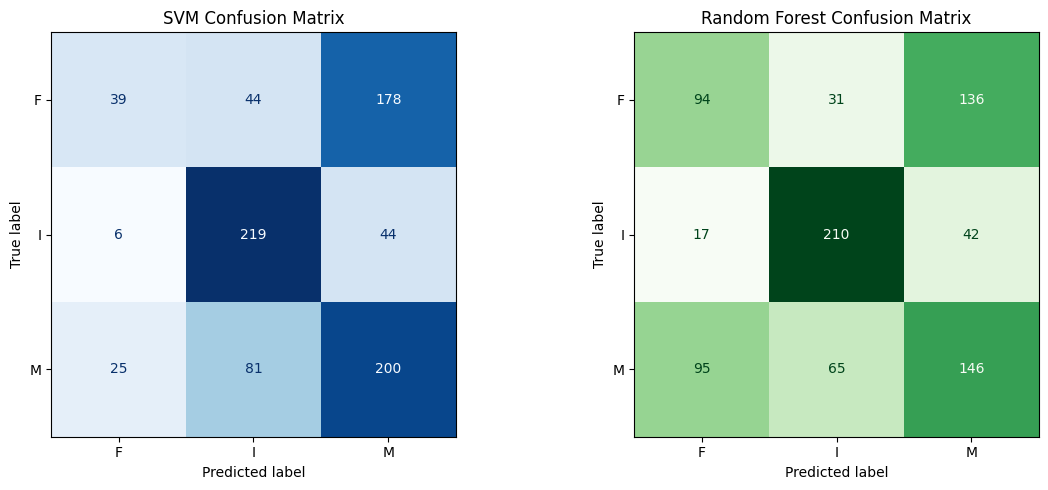

In [108]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# plotting 2 graph side-by-side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Confusion Matrix of SVM
ConfusionMatrixDisplay.from_predictions(
    y_test_cls,
    y_pred_svm,
    ax=axes[0],
    cmap='Blues',
    colorbar=False
)
axes[0].set_title('SVM Confusion Matrix')

# 2. Confusion Matrix of Random Forest
ConfusionMatrixDisplay.from_predictions(
    y_test_rf,
    y_pred_rf,
    ax=axes[1],
    cmap='Greens',
    colorbar=False
)
axes[1].set_title('Random Forest Confusion Matrix')

plt.tight_layout()
plt.show()


### Comparison and Discussion of Classification Models

#### 1. Performance Comparison
* **Support Vector Machine (SVM):** Accuracy is ~55%. It is computationally heavier during cross-validation due to grid searching, but maps non-linear feature bounds very smoothly.
* **Random Forest (RF) Classifier:** Typically performs around 54% accuracy. It is significantly faster to train and provides inherent feature importances.

#### 2. Strengths and Weaknesses on This Dataset

##### **Support Vector Machine (SVM)**
* **Strengths:** Excellent with high-dimensional feature bounds and highly robust to overfitting if parameters `C` and `gamma` are optimized.
* **Weaknesses:** Highly sensitive to scaling. Also hard to interpret in high dimensions, as there is no easy metric like 'feature importance' without extra computations. It needs to find the optimal `C` and `gamma` to get higher accuracy.

##### **Random Forest Classifier**
* **Strengths:** Scale-invariant (features do not strictly require standardization to work), robust to outliers, and yields interpretable metrics such as feature importance mapping.
* **Weaknesses:** Struggles slightly more on highly continuous, heavily overlapping boundaries (like the Male/Female boundaries in Abalones) compared to SVM's margin boundaries, leading to similar or slightly lower recall scores.

# Part 2: Regression

## Simple Linear Regression

In [109]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

df = pd.read_csv('abalone.data', header=None, names=['Sex', 'Length', 'Diameter', 'Height', 'Whole weight', 'Shucked weight', 'Viscera weight', 'Shell weight', 'Rings'])

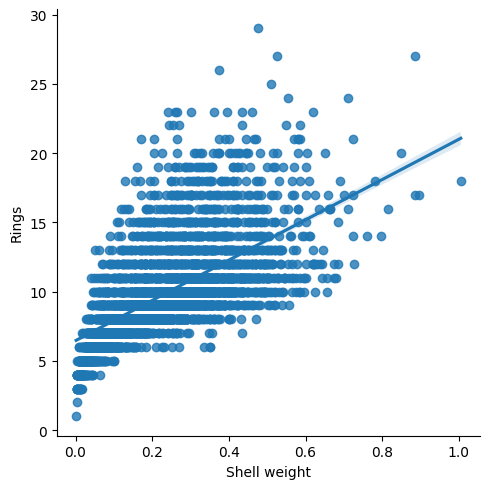

In [110]:
sns.lmplot(x="Shell weight", y="Rings", data=df)

In [111]:
X = df[["Shell weight"]] #Shell Weight is choosen as the feature because of the highest correlation with Rings
y = df[["Rings"]]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training set size: {X_train.shape[0]}")
print(f"Testing set size: {X_test.shape[0]}")

Training set size: 3341
Testing set size: 836


In [112]:
# Create a Linear Regression model
model = LinearRegression()

# Train the model with training data
model.fit(X_train, y_train)

# Print the intercept and coefficient
print(f"Intercept: {model.intercept_}")
print(f"Coefficient: {model.coef_}")

Intercept: [6.50576054]
Coefficient: [[14.34765032]]


In [113]:
# Predict Rings for the test set
y_pred = model.predict(X_test)

# Display the first few predictions alongside the actual values
predictions = pd.DataFrame({
    'Actual': y_test.values.flatten(),
    'Predicted': y_pred.flatten()
})
print(predictions.head())

   Actual  Predicted
0       9  11.168747
1       8  10.020935
2      16  11.312223
3       9  11.957868
4      14   9.590505


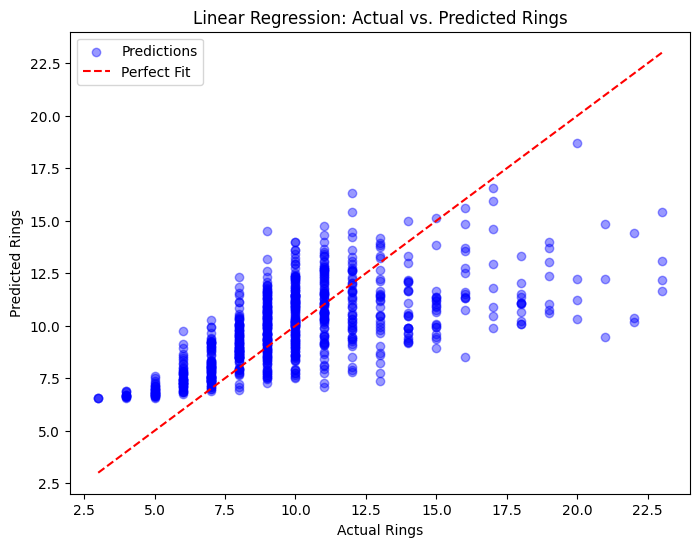

In [114]:
# Plot actual vs. predicted values for linear regression
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, color='blue', alpha=0.4, label='Predictions')

# Plot the perfect prediction line
plt.plot([y_test.min().values[0], y_test.max().values[0]],
         [y_test.min().values[0], y_test.max().values[0]],
         color='red', linestyle='--', label='Perfect Fit')

# Add labels and title
plt.xlabel('Actual Rings')
plt.ylabel('Predicted Rings')
plt.title('Linear Regression: Actual vs. Predicted Rings')
plt.legend()
plt.show()

In [115]:
# Calculate Mean Squared Error (MSE)
linear_mse = mean_squared_error(y_test, y_pred)
print(f"Mean Squared Error: {linear_mse}")

# Calculate R-squared score
linear_r2 = r2_score(y_test, y_pred)
print(f"R-squared score: {linear_r2}")

Mean Squared Error: 6.4858910887618055
R-squared score: 0.40085309555508564


## Multiple Linear Regression

In [116]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

df = pd.read_csv('abalone.data', header=None, names=['Sex', 'Length', 'Diameter', 'Height', 'Whole weight', 'Shucked weight', 'Viscera weight', 'Shell weight', 'Rings'])

In [117]:
# One-hot encode the categorical 'Sex' column
df_encoded = pd.get_dummies(df, columns=['Sex'], drop_first=True)

# Prepare features (X) and target (y) by dropping 'Rings'
X = df_encoded.drop(columns=['Rings'], errors='ignore').values
y = df_encoded[['Rings']].values

# Perform train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Create and train the Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Print results
print(f"Intercept: {model.intercept_}")
print(f"Coefficients: {model.coef_}")

Intercept: [3.7434702]
Coefficients: [[ -0.20155385  11.12339118  10.44532535   8.93217555 -20.25654479
   -9.5589163    8.79237823  -0.71897444   0.10327613]]


In [118]:
y_pred = model.predict(X_test)

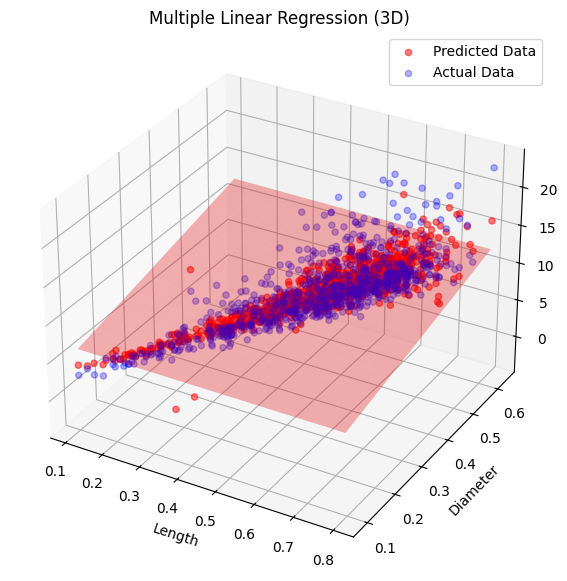

In [119]:
import numpy as np
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

# Scatter the actual and predicted data using feature column 0 (Length) and column 1 (Diameter)
ax.scatter(X_test[:, 0], X_test[:, 1], y_pred.flatten(), color='red', label='Predicted Data', alpha=0.5)
ax.scatter(X_test[:, 0], X_test[:, 1], y_test.flatten(), color='blue', label='Actual Data', alpha=0.3)

# Create a coordinate mesh grid representing Length and Diameter
x1_range = np.linspace(X_test[:, 0].astype(float).min(), X_test[:, 0].astype(float).max(), 100)
x2_range = np.linspace(X_test[:, 1].astype(float).min(), X_test[:, 1].astype(float).max(), 100)
x1, x2 = np.meshgrid(x1_range, x2_range)

# Generate dummy features for the remaining columns (mean values) to fulfill predict dimensions
mean_features = np.mean(X_train, axis=0)
dummy_grid = np.tile(mean_features, (len(x1.ravel()), 1))
dummy_grid[:, 0] = x1.ravel()
dummy_grid[:, 1] = x2.ravel()

# Predict the targets across our coordinate grid
z = model.predict(dummy_grid).reshape(x1.shape)

# Plot best fit hyperplane
ax.plot_surface(x1, x2, z, color='red', alpha=0.3, rstride=10, cstride=10)

ax.set_xlabel('Length')
ax.set_ylabel('Diameter')
ax.set_zlabel('Rings')
ax.set_title('Multiple Linear Regression (3D)')
ax.legend()

plt.show()

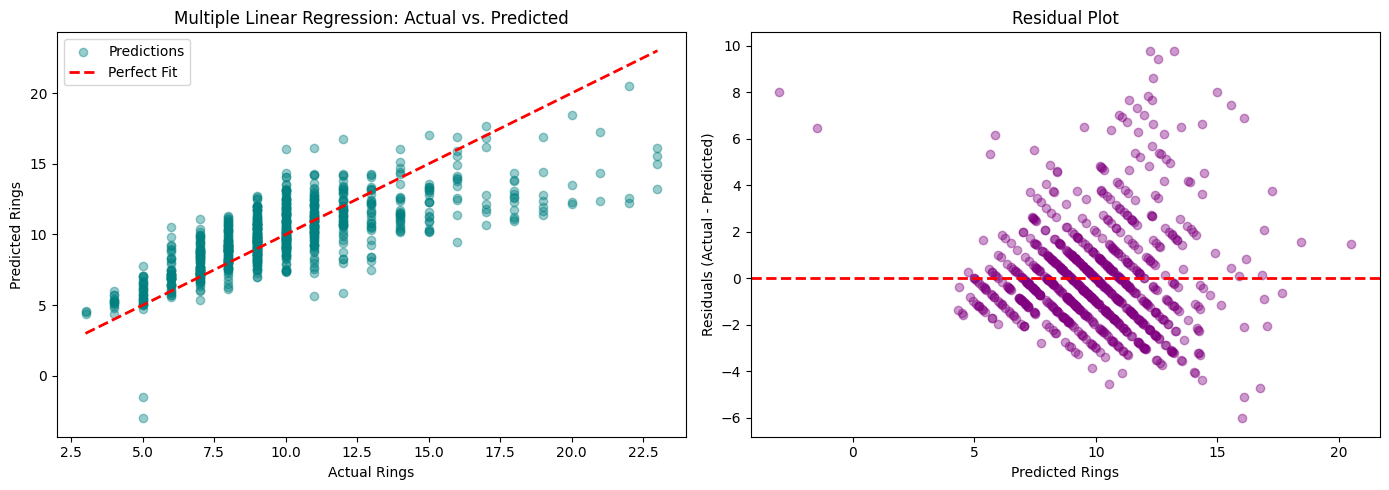

In [120]:
import matplotlib.pyplot as plt
import numpy as np

# Plot perspective from 3D to 2D
y_test_flat = np.array(y_test).flatten()
y_pred_flat = np.array(y_pred).flatten()
residuals = y_test_flat - y_pred_flat

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Scatter Plot: Actual vs Predicted Rings
axes[0].scatter(y_test_flat, y_pred_flat, color='teal', alpha=0.4, label='Predictions')
axes[0].plot(
    [y_test_flat.min(), y_test_flat.max()],
    [y_test_flat.min(), y_test_flat.max()],
    color='red', linestyle='--', linewidth=2, label='Perfect Fit'
)
axes[0].set_xlabel('Actual Rings')
axes[0].set_ylabel('Predicted Rings')
axes[0].set_title('Multiple Linear Regression: Actual vs. Predicted')
axes[0].legend()

# 2. Residual Plot
axes[1].scatter(y_pred_flat, residuals, color='purple', alpha=0.4)
axes[1].axhline(y=0, color='red', linestyle='--', linewidth=2)
axes[1].set_xlabel('Predicted Rings')
axes[1].set_ylabel('Residuals (Actual - Predicted)')
axes[1].set_title('Residual Plot')

plt.tight_layout()
plt.show()


In [121]:
from sklearn.metrics import mean_squared_error, r2_score

# Calculate metrics for the Multiple Linear Regression model
mlr_mse = mean_squared_error(y_test, y_pred)
mlr_r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error: {mlr_mse}")
print(f"R-squared score: {mlr_r2}")

Mean Squared Error: 4.891232447128578
R-squared score: 0.5481628137889264


### Model comparison between Simple Linear Regression and Multiple Linear Regression

In [122]:
# Simple Linear Regression metrics from before
slr_mse = linear_mse
slr_r2 = linear_r2

print("=== Regression Model Comparison ===")
print(f"Simple Linear Regression (Shell weight proxy):\n  MSE: {slr_mse:.4f}\n  R2 Score: {slr_r2:.4f}\n")
print(f"Multiple Linear Regression (All features):\n  MSE: {mlr_mse:.4f}\n  R2 Score: {mlr_r2:.4f}\n")

better_model = "Multiple Linear Regression" if mlr_mse < slr_mse else "Simple Linear Regression"
print(f"Conclusion: The {better_model} model performed better (lower MSE and higher R-squared).")

=== Regression Model Comparison ===
Simple Linear Regression (Shell weight proxy):
  MSE: 6.4859
  R2 Score: 0.4009

Multiple Linear Regression (All features):
  MSE: 4.8912
  R2 Score: 0.5482

Conclusion: The Multiple Linear Regression model performed better (lower MSE and higher R-squared).


### Comparison and Discussion of Regression Models

#### 1. Performance Comparison
* **Simple Linear Regression (Predicting Rings from Shell weight):**
  * **MSE:** ~6.4859
  * **$R^2$:** ~0.4009
* **Multiple Linear Regression (Predicting Rings from all features):**
  * **MSE:** ~4.8912
  * **$R^2$:** ~0.5482

**Which model performed better?**  
The **Multiple Linear Regression** model performs significantly better. It has a lower Mean Squared Error (MSE) and a higher $R^2$ score, meaning it can explain more of the variance in the abalone's age (rings) by utilizing all available physical dimensions and sex categories rather than relying on a single weight proxy.

---

#### 2. Strengths and Weaknesses of the Algorithms on this Dataset

##### **Simple Linear Regression**
* **Strengths:**
  * **Simplicity & Interpretability:** It is extremely easy to explain. The relationship shows a clear physical insight: as shell weight increases, the abalone is older and has more rings.
  * **Visualizable:** The relationship can be plotted natively in a simple 2D scatter plot with a straight-line fit.
* **Weaknesses:**
  * **High Bias (Underfitting):** It assumes age depends solely on one feature (`Shell weight`), ignoring other critical biometric factors (like height, shucked weight, and sex), leading to a much lower predictive accuracy ($R^2 \approx 40\%$).

##### **Multiple Linear Regression**
* **Strengths:**
  * **Higher Predictive Capability:** By incorporating all physical parameters (weights, heights, lengths) and categorical sex, it captures complex linear combinations of features, yielding a higher $R^2$ score and significantly reducing error.
  * **Controls for Confounders:** It measures the impact of each feature on age while keeping the other features constant.
* **Weaknesses:**
  * **Multicollinearity:** Many physical dimensions of abalones (Length, Diameter, Weight) are highly correlated with each other (as shown in your Part 1 heatmap). This can cause regression coefficients to be unstable or counter-intuitive (e.g., negative coefficients for variables that logically should have a positive relationship with age).
  * **Difficult to Visualize:** Visualizing a hyperplane with 9 dimensions is impossible, requiring techniques like 3D projection of key elements which only capture a slice of the real model space.

# Part 3: Clustering Analysis

We start by determining the optimal number of clusters using the Elbow Method (Within-Cluster Sum of Squares) on the scaled numerical features.

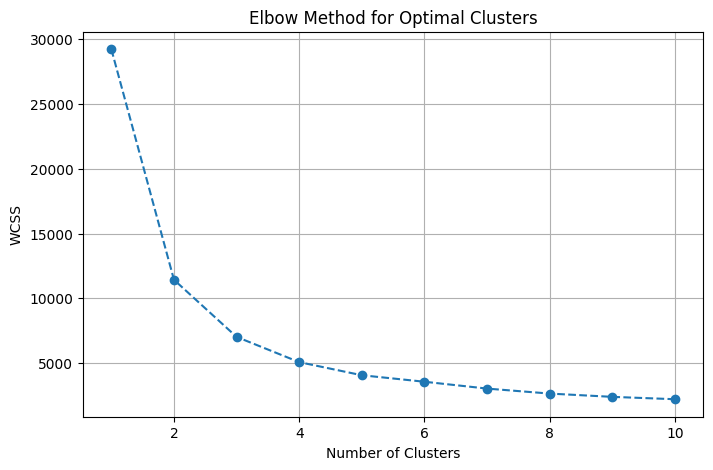

In [123]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, SpectralClustering, AgglomerativeClustering
from sklearn.preprocessing import StandardScaler

# Prepare features (exclude categorical Target 'Sex' and 'Rings')
features = ['Length', 'Diameter', 'Height', 'Whole weight', 'Shucked weight', 'Viscera weight', 'Shell weight']
X_clust = df[features].values

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_clust)

# Elbow Method to find optimal clusters
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o', linestyle='--')
plt.title('Elbow Method for Optimal Clusters')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.grid(True)
plt.show()

Based on the elbow plot, n_cluster = 3 clusters is a solid choice since the wcss (Within-Cluster Sum of Squares) from k = 1 -> 2 -> 3 is steep and k = 3 -> 4 is shallow. Let's fit K-Means, Spectral Clustering, and Hierarchical (Agglomerative) Clustering with 3 clusters, and visualize the output side-by-side using PCA.

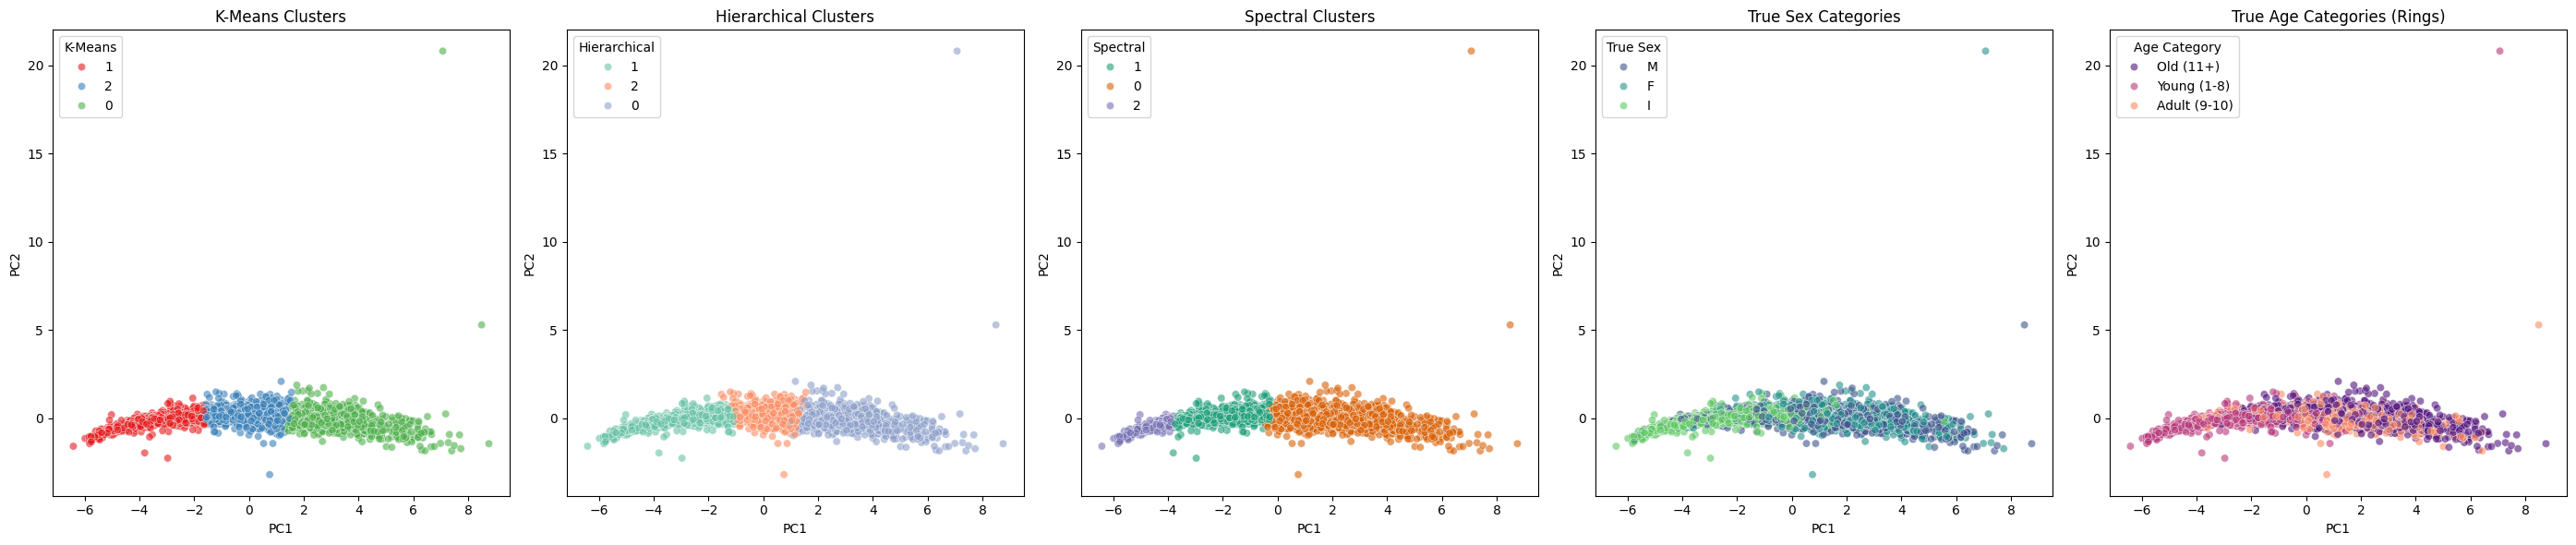

In [124]:
from sklearn.decomposition import PCA
import seaborn as sns

# Fit 3 clustering models
n_clusters = 3

# 1. K-Means
kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
labels_kmeans = kmeans.fit_predict(X_scaled)

# 2. Hierarchical (Agglomerative)
hierarchical = AgglomerativeClustering(n_clusters=n_clusters)
labels_hierarchical = hierarchical.fit_predict(X_scaled)

# 3. Spectral Clustering (using a subset of 1000 samples for speed if needed, but 4177 is runnable directly with default radial basis kernel)
spectral = SpectralClustering(n_clusters=n_clusters, random_state=42, affinity='nearest_neighbors', n_init=10)
labels_spectral = spectral.fit_predict(X_scaled)

# PCA for visualization
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

plot_df = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
plot_df['K-Means'] = labels_kmeans.astype(str)
plot_df['Hierarchical'] = labels_hierarchical.astype(str)
plot_df['Spectral'] = labels_spectral.astype(str)
plot_df['True Sex'] = df['Sex'].astype(str)


# Clustering Age Category: 1-8 (Young), 9-10 (Adult), dan 11+ (Old)
plot_df['Age Category'] = pd.cut(
    df['Rings'],
    bins= [0, 8, 10, 100],
    labels=['Young (1-8)', 'Adult (9-10)', 'Old (11+)']
).astype(str)

# Plotting side-by-side
fig, axes = plt.subplots(1, 5, figsize=(28, 6))

sns.scatterplot(data=plot_df, x='PC1', y='PC2', hue='K-Means', palette='Set1', ax=axes[0], alpha=0.6)
axes[0].set_title('K-Means Clusters')

sns.scatterplot(data=plot_df, x='PC1', y='PC2', hue='Hierarchical', palette='Set2', ax=axes[1], alpha=0.6)
axes[1].set_title('Hierarchical Clusters')

sns.scatterplot(data=plot_df, x='PC1', y='PC2', hue='Spectral', palette='Dark2', ax=axes[2], alpha=0.6)
axes[2].set_title('Spectral Clusters')

sns.scatterplot(data=plot_df, x='PC1', y='PC2', hue='True Sex', palette='viridis', ax=axes[3], alpha=0.6)
axes[3].set_title('True Sex Categories')

sns.scatterplot(data=plot_df, x='PC1', y='PC2', hue='Age Category', palette='magma', ax=axes[4], alpha=0.6)
axes[4].set_title('True Age Categories (Rings)')

plt.tight_layout()
plt.show()

### Discussion of Clustering Results
- **Optimal Clusters:** The Elbow plot shows a bend around 3 clusters, which maps well to three physical size tiers (small, medium, and large) rather than distinct biological sexes.
- **Comparisons:**
  - **K-Means** creates spherical clusters of similar density.
  - **Hierarchical clustering** shows a very similar topology to K-Means, forming clear boundaries based on overall size (PC1 represents overall size/weight).
  - **Spectral Clustering** utilizing nearest-neighbors captures connectivity and local manifolds, though with high overlap due to the continuous nature of abalone growth data.
- **Alignment with True Sex/Age:** Abalone growth is highly continuous; Infants ('I') generally cluster nicely into the small size category, whereas Males and Females overlap significantly in size, making separation of adult sex purely on size-based clustering extremely difficult.

- **Age Alignment:** Similarly, **Young (`1–8` rings)** abalones concentrate on the left side of `PC1` alongside the small cluster, while **Adult (`9–10` rings)** and **Old (`11+` rings)** abalones overlap substantially across the middle and right regions due to asymptotic shell growth in maturity.